### Align MOD16 to 500m

In [2]:
import os
import rasterio
from rasterio.warp import reproject, Resampling

# ======================
# FOLDERS
# ======================
pet_folder = r"C:\Users\gerii\Documents\projects\tekeze\MOD16"
ref_folder = r"C:\Users\gerii\Documents\projects\tekeze\CHIRPS_500m"

out_folder = r"C:\Users\gerii\Documents\projects\tekeze\MOD16_500m"
os.makedirs(out_folder, exist_ok=True)

# ======================
# LOOP FILES
# ======================
files = [f for f in os.listdir(pet_folder) if f.endswith(".tif")]

for f in files:

    pet_path = os.path.join(pet_folder, f)

    # match CHIRPS file
    date = f.replace("PET_", "")
    ref_path = os.path.join(ref_folder, date)

    if not os.path.exists(ref_path):
        continue

    with rasterio.open(ref_path) as ref:
        ref_data = ref.read(1)
        ref_transform = ref.transform
        ref_crs = ref.crs
        ref_shape = ref_data.shape

    with rasterio.open(pet_path) as src:

        pet_data = src.read(1)

        dst = rasterio.open(
            os.path.join(out_folder, f),
            'w',
            driver='GTiff',
            height=ref_shape[0],
            width=ref_shape[1],
            count=1,
            dtype=pet_data.dtype,
            crs=ref_crs,
            transform=ref_transform,
        )

        reproject(
            source=pet_data,
            destination=rasterio.band(dst, 1),
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=ref_transform,
            dst_crs=ref_crs,
            resampling=Resampling.bilinear   # ✔ best for PET
        )

        dst.close()

    print("Aligned:", f)

print("All PET aligned ✔")

Aligned: PET_2000_01.tif
Aligned: PET_2000_02.tif
Aligned: PET_2000_03.tif
Aligned: PET_2000_04.tif
Aligned: PET_2000_05.tif
Aligned: PET_2000_06.tif
Aligned: PET_2000_07.tif
Aligned: PET_2000_08.tif
Aligned: PET_2000_09.tif
Aligned: PET_2000_10.tif
Aligned: PET_2000_11.tif
Aligned: PET_2000_12.tif
Aligned: PET_2001_01.tif
Aligned: PET_2001_02.tif
Aligned: PET_2001_03.tif
Aligned: PET_2001_04.tif
Aligned: PET_2001_05.tif
Aligned: PET_2001_06.tif
Aligned: PET_2001_07.tif
Aligned: PET_2001_08.tif
Aligned: PET_2001_09.tif
Aligned: PET_2001_10.tif
Aligned: PET_2001_11.tif
Aligned: PET_2001_12.tif
Aligned: PET_2002_01.tif
Aligned: PET_2002_02.tif
Aligned: PET_2002_03.tif
Aligned: PET_2002_04.tif
Aligned: PET_2002_05.tif
Aligned: PET_2002_06.tif
Aligned: PET_2002_07.tif
Aligned: PET_2002_08.tif
Aligned: PET_2002_09.tif
Aligned: PET_2002_10.tif
Aligned: PET_2002_11.tif
Aligned: PET_2002_12.tif
Aligned: PET_2003_01.tif
Aligned: PET_2003_02.tif
Aligned: PET_2003_03.tif
Aligned: PET_2003_04.tif


### SPEI without using spei library

In [4]:
import os
import numpy as np
import rasterio
from scipy.ndimage import uniform_filter1d

# ======================
# FOLDERS
# ======================
chirps_folder = r"C:\Users\gerii\Documents\projects\tekeze\CHIRPS_500m"
pet_folder    = r"C:\Users\gerii\Documents\projects\tekeze\MOD16_500m"

out_folder = r"C:\Users\gerii\Documents\projects\tekeze\SPEI"
os.makedirs(out_folder, exist_ok=True)

# ======================
# FILE LIST (2000–2025)
# ======================
years = range(2000, 2026)

dates = []
for y in years:
    for m in range(1, 13):
        dates.append(f"{y}_{m:02d}")

# ======================
# STACK DATA
# ======================
stack_P = []
stack_PET = []

print("Loading data...")

for d in dates:

    chirps_path = os.path.join(chirps_folder, f"{d}.tif")
    pet_path    = os.path.join(pet_folder, f"PET_{d}.tif")

    if not (os.path.exists(chirps_path) and os.path.exists(pet_path)):
        continue

    with rasterio.open(chirps_path) as src:
        P = src.read(1).astype("float32")
        profile = src.profile

    with rasterio.open(pet_path) as src:
        PET = src.read(1).astype("float32")

    # mask invalid
    P[P < 0] = np.nan
    PET[PET < 0] = np.nan

    stack_P.append(P)
    stack_PET.append(PET)

stack_P = np.array(stack_P)
stack_PET = np.array(stack_PET)

print("Stack shape:", stack_P.shape)

# ======================
# WATER BALANCE
# ======================
D = stack_P - stack_PET

# ======================
# FUNCTION: SPEI
# ======================
def compute_spei(data, scale):

    # moving average
    data_scaled = uniform_filter1d(data, size=scale, axis=0, mode='nearest')

    # mean & std
    mean = np.nanmean(data_scaled, axis=0)
    std  = np.nanstd(data_scaled, axis=0)

    # mask invalid pixels (all-NaN or zero variance)
    invalid = np.isnan(mean) | (std == 0)

    std[invalid] = np.nan

    spei = (data_scaled - mean) / std

    # force invalid pixels to NaN
    spei[:, invalid] = np.nan

    return spei

# ======================
# COMPUTE SCALES
# ======================
scales = [1, 3, 6]

for scale in scales:

    print(f"\nProcessing SPEI-{scale}...")

    spei = compute_spei(D, scale)

    scale_folder = os.path.join(out_folder, f"SPEI_{scale}")
    os.makedirs(scale_folder, exist_ok=True)

    for i, d in enumerate(dates[:spei.shape[0]]):

        out_path = os.path.join(scale_folder, f"SPEI{scale}_{d}.tif")

        profile.update(dtype=rasterio.float32, count=1)

        with rasterio.open(out_path, "w", **profile) as dst:
            dst.write(spei[i].astype("float32"), 1)

    print(f"SPEI-{scale} done ✔")

print("\nAll SPEI scales completed ✔")

Loading data...
Stack shape: (312, 679, 819)

Processing SPEI-1...


C:\Users\geri geri\AppData\Local\Temp\ipykernel_404\796918395.py:74: RuntimeWarning: Mean of empty slice
  mean = np.nanmean(data_scaled, axis=0)


SPEI-1 done ✔

Processing SPEI-3...
SPEI-3 done ✔

Processing SPEI-6...
SPEI-6 done ✔

All SPEI scales completed ✔


### visulaize SPEI3 

Files found: 12


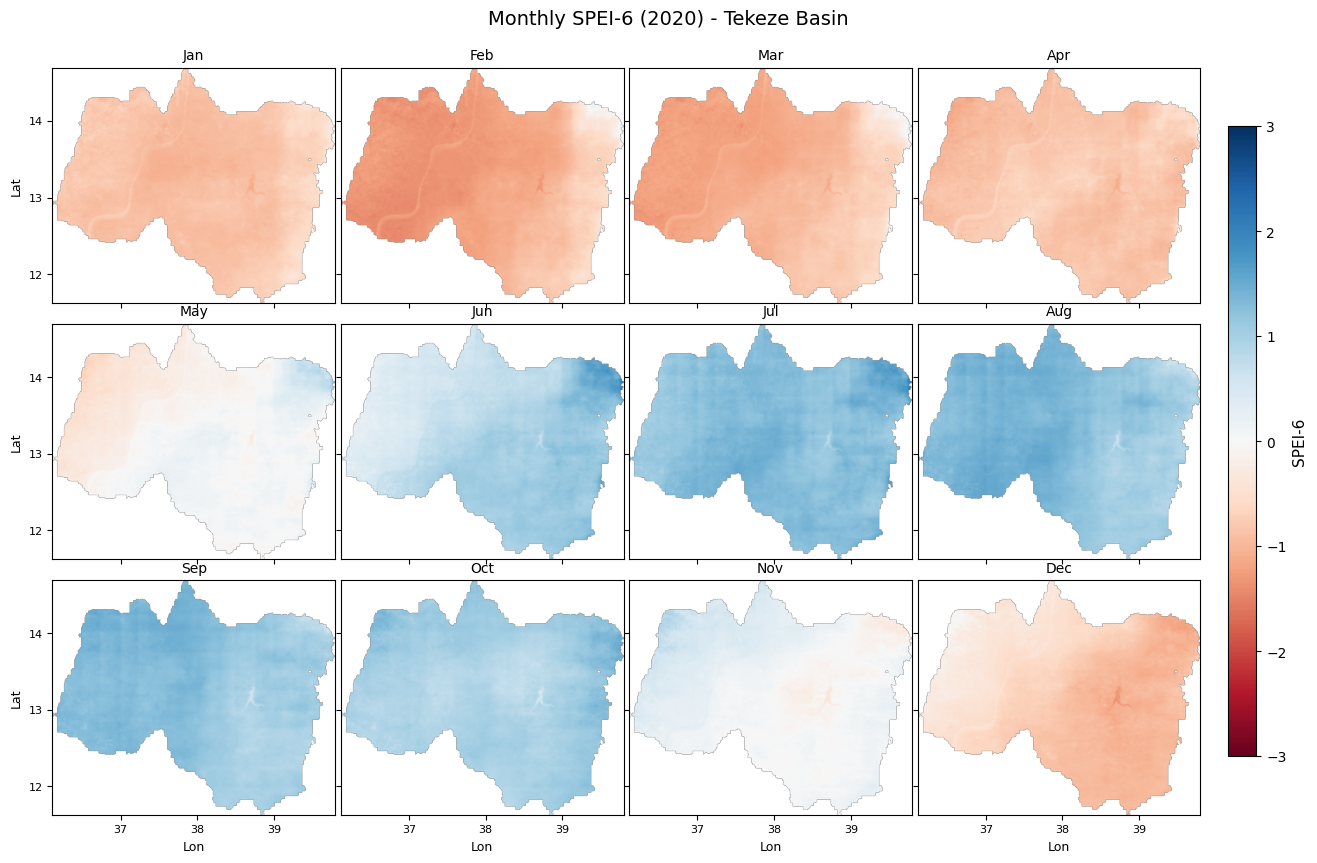

In [15]:
import os
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# ======================
# FOLDER
# ======================
folder = r"C:\Users\gerii\Documents\projects\tekeze\SPEI\SPEI_6"

files = sorted([
    f for f in os.listdir(folder)
    if f.startswith("SPEI6_2020") and f.endswith(".tif")
])

print("Files found:", len(files))

# ======================
# FIGURE
# ======================
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
axes = axes.flatten()

months = ["Jan","Feb","Mar","Apr","May","Jun",
          "Jul","Aug","Sep","Oct","Nov","Dec"]

# SPEI range (standard)
vmin = -3
vmax = 3

# ======================
# PLOT LOOP
# ======================
for i, f in enumerate(files):

    path = os.path.join(folder, f)

    with rasterio.open(path) as src:
        data = src.read(1).astype("float32")

        # mask invalid
        data[np.abs(data) > 10] = np.nan

        bounds = src.bounds
        extent = [bounds.left, bounds.right, bounds.bottom, bounds.top]

    ax = axes[i]

    im = ax.imshow(
        data,
        extent=extent,
        origin="upper",
        cmap="RdBu",   # dry=red, wet=blue
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(months[i], fontsize=10)

    # ======================
    # 1-degree grid
    # ======================
    ax.xaxis.set_major_locator(MultipleLocator(1))
    ax.yaxis.set_major_locator(MultipleLocator(1))
    ax.tick_params(labelsize=8)

    # ======================
    # AXIS STYLE
    # ======================
    row = i // 4
    col = i % 4

    if col == 0:
        ax.set_ylabel("Lat", fontsize=9)
    else:
        ax.set_yticklabels([])

    if row == 2:
        ax.set_xlabel("Lon", fontsize=9)
    else:
        ax.set_xticklabels([])

# ======================
# REMOVE EMPTY AXES
# ======================
for j in range(len(files), 12):
    axes[j].axis("off")

# ======================
# LAYOUT (tight like your NDVI)
# ======================
plt.subplots_adjust(
    left=0.06,
    right=0.88,
    top=0.92,
    bottom=0.08,
    wspace=0.02,
    hspace=0.05
)

# ======================
# COLORBAR (right side)
# ======================
cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.7])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label("SPEI-6", fontsize=11)

# ======================
# TITLE
# ======================
plt.suptitle("Monthly SPEI-6 (2020) - Tekeze Basin", fontsize=14)

# ======================
# SAVE
# ======================
fig.canvas.draw()
fig.savefig(
    r"C:\Users\gerii\Documents\projects\tekeze\SPEI\SPEI_6\SPEI6_2020_map.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [1]:
import os
import numpy as np
import rasterio

# ======================
# FOLDERS
# ======================
chirps_folder = r"C:\Users\gerii\Documents\projects\tekeze\CHIRPS_500m"
pet_folder    = r"C:\Users\gerii\Documents\projects\tekeze\MOD16_500m"

out_folder = r"C:\Users\gerii\Documents\projects\tekeze\SPEI\SPEI_12"
os.makedirs(out_folder, exist_ok=True)

# ======================
# FILE LIST (2000–2025)
# ======================
years = range(2000, 2026)

dates = []
for y in years:
    for m in range(1, 13):
        dates.append(f"{y}_{m:02d}")

# ======================
# STACK DATA
# ======================
stack_P = []
stack_PET = []

print("Loading data...")

valid_dates = []

for d in dates:

    chirps_path = os.path.join(chirps_folder, f"{d}.tif")
    pet_path    = os.path.join(pet_folder, f"PET_{d}.tif")

    if not (os.path.exists(chirps_path) and os.path.exists(pet_path)):
        print(f"Missing data for {d}")
        continue

    with rasterio.open(chirps_path) as src:
        P = src.read(1).astype("float32")
        profile = src.profile

    with rasterio.open(pet_path) as src:
        PET = src.read(1).astype("float32")

    # mask invalid values
    P[P < 0] = np.nan
    PET[PET < 0] = np.nan

    stack_P.append(P)
    stack_PET.append(PET)

    valid_dates.append(d)

stack_P = np.array(stack_P)
stack_PET = np.array(stack_PET)

print("Stack shape:", stack_P.shape)

# ======================
# WATER BALANCE
# ======================
D = stack_P - stack_PET

# ======================
# COMPUTE SPEI-12
# ======================
print("\nComputing SPEI-12...")

scale = 12

# rolling 12-month mean
D_scaled = np.full_like(D, np.nan)

for t in range(scale - 1, D.shape[0]):

    window = D[t - scale + 1:t + 1]

    D_scaled[t] = np.nanmean(window, axis=0)

# climatological mean and std
mean = np.nanmean(D_scaled, axis=0)
std  = np.nanstd(D_scaled, axis=0)

# invalid pixels
invalid = np.isnan(mean) | (std == 0)

std[invalid] = np.nan

# standardization
spei12 = (D_scaled - mean) / std

# force invalid pixels to NaN
spei12[:, invalid] = np.nan

# ======================
# SAVE OUTPUTS
# ======================
print("\nSaving SPEI-12 rasters...")

profile.update(
    dtype=rasterio.float32,
    count=1,
    nodata=np.nan
)

for i, d in enumerate(valid_dates):

    out_path = os.path.join(out_folder, f"SPEI12_{d}.tif")

    with rasterio.open(out_path, "w", **profile) as dst:
        dst.write(spei12[i].astype("float32"), 1)

print("\nSPEI-12 completed successfully ✔")

Loading data...
Stack shape: (312, 679, 819)

Computing SPEI-12...


C:\Users\geri geri\AppData\Local\Temp\ipykernel_8904\3412507861.py:83: RuntimeWarning: Mean of empty slice
  D_scaled[t] = np.nanmean(window, axis=0)
C:\Users\geri geri\AppData\Local\Temp\ipykernel_8904\3412507861.py:86: RuntimeWarning: Mean of empty slice
  mean = np.nanmean(D_scaled, axis=0)
C:\Users\gerii\miniconda1\envs\envgg\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,



Saving SPEI-12 rasters...

SPEI-12 completed successfully ✔


### Barplot

Loading SPEI-1...
Loading SPEI-3...
Loading SPEI-6...
Loading SPEI-12...


C:\Users\geri geri\AppData\Local\Temp\ipykernel_10844\1570572497.py:40: RuntimeWarning: Mean of empty slice
  mean_val = np.nanmean(arr)



Saved figure:
C:\Users\gerii\Documents\projects\tekeze\indices\SPEI\SPEI_4panel_barplot.png


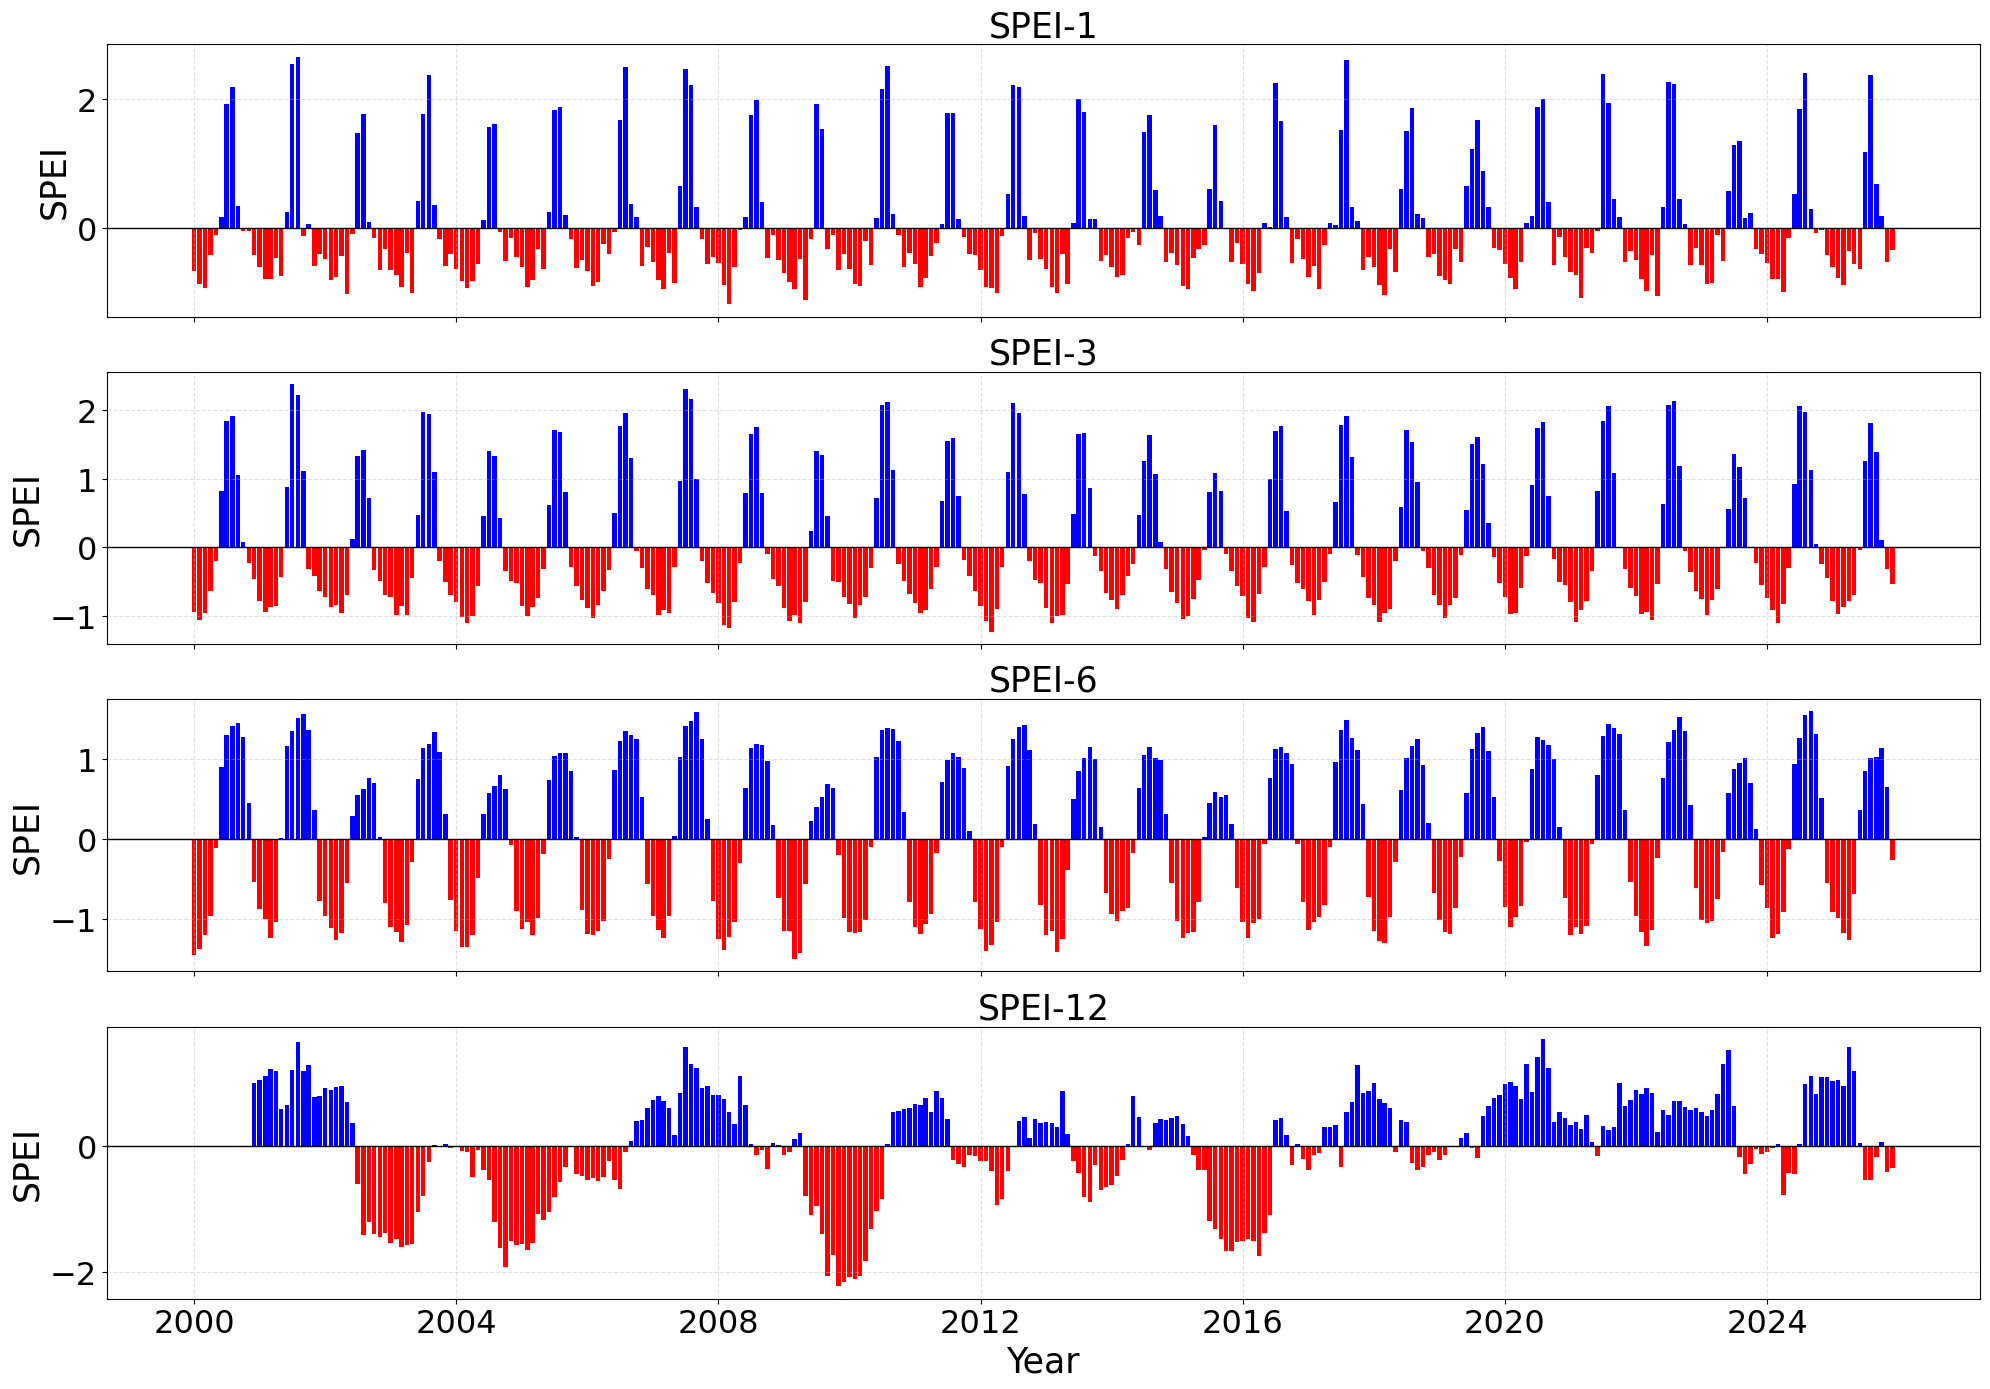

In [4]:
import os
import numpy as np
import rasterio
import matplotlib.pyplot as plt
import pandas as pd

# =====================================================
# MAIN FOLDER
# =====================================================
base_folder = r"C:\Users\gerii\Documents\projects\tekeze\indices\SPEI"

scales = [1, 3, 6, 12]

# =====================================================
# FUNCTION TO LOAD SPEI SERIES
# =====================================================
def load_spei_series(folder, scale):

    scale_folder = os.path.join(folder, f"SPEI_{scale}")

    files = sorted([
        f for f in os.listdir(scale_folder)
        if f.endswith(".tif")
    ])

    dates = []
    values = []

    for f in files:

        path = os.path.join(scale_folder, f)

        with rasterio.open(path) as src:
            arr = src.read(1).astype(np.float32)

        # mask invalid values
        arr[arr < -9990] = np.nan

        # spatial mean
        mean_val = np.nanmean(arr)

        # filename example:
        # SPEI1_2000_01.tif

        name = os.path.splitext(f)[0]

        parts = name.split("_")

        year = parts[-2]
        month = parts[-1]

        date = pd.to_datetime(f"{year}-{month}")

        dates.append(date)
        values.append(mean_val)

    return dates, values

# =====================================================
# LOAD ALL SPEI DATA
# =====================================================
all_data = {}

for scale in scales:

    print(f"Loading SPEI-{scale}...")

    d, v = load_spei_series(base_folder, scale)

    all_data[scale] = (d, v)

# =====================================================
# CREATE FIGURE
# =====================================================
fig, axes = plt.subplots(
    4,
    1,
    figsize=(20, 14),
    sharex=True
)

# =====================================================
# PLOT EACH SCALE
# =====================================================
for ax, scale in zip(axes, scales):

    dates, values = all_data[scale]

    # color bars
    colors = [
        "blue" if v >= 0 else "red"
        for v in values
    ]

    ax.bar(
        dates,
        values,
        color=colors,
        width=25
    )

    # zero line
    ax.axhline(
        0,
        color='black',
        linewidth=1
    )

    # subplot title
    ax.set_title(
        f"SPEI-{scale}",
        fontsize=25,    
    )
#fontweight='bold'
    # y-axis label
    ax.set_ylabel(
        "SPEI",
        fontsize=25
    )

    # larger tick labels
    ax.tick_params(
        axis='both',
        labelsize=23
    )

    # grid
    ax.grid(
        True,
        linestyle='--',
        alpha=0.4
    )

# =====================================================
# X LABEL
# =====================================================
plt.xlabel(
    "Year",
    fontsize=25
)

# =====================================================
# LAYOUT
# =====================================================
plt.tight_layout()

# =====================================================
# SAVE FIGURE
# =====================================================
out_path = os.path.join(
    base_folder,
    "SPEI_4panel_barplot.png"
)

plt.savefig(
    out_path,
    dpi=350,
    bbox_inches='tight'
)

print(f"\nSaved figure:\n{out_path}")

# =====================================================
# SHOW FIGURE
# =====================================================
plt.show()